# Домашнее задание 1

Задача — по прошлым отзывам пользователя подобрать ему десять товаров из категории Video Games, которые он ещё не оценивал. В эту категорию входят сами игры, их отдельные издания и игровые аксессуары. Для этого в работе сравниваются пять моделей рекомендаций.

Данные — [Amazon Review Data 2018 (UCSD)](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/). Код моделей лежит в папке `models/`, общие функции — в `utils/`.

## 0. Загрузка данных и запуск

**Данные.** Используется категория Video Games из [Amazon Review Data 2018 (UCSD)](https://cseweb.ucsd.edu/~jmcauley/datasets/amazon_v2/): файл отзывов и файл метаданных. При первом запуске ноутбук сам загружает оба файла с официального сервера и проверяет их размер и контрольные суммы SHA-256.

Файлы сохраняются во временную папку `amazon_video_games_cache`. Другую папку можно задать через переменную окружения `RECSYS_CACHE_DIR`. При повторном запуске данные берутся из кеша.

**Запуск локально.**

1. Установить зависимости: `pip install -r requirements.txt`
2. Открыть `experiments.ipynb` и выполнить все ячейки по порядку.

## 1. Загрузка и описание данных

Используются два файла. В основном каждая строка — это отзыв: ASIN товара, анонимный ID пользователя, оценка от 1 до 5 и время публикации. Во втором файле лежат названия, бренды и категории товаров. Оба файла взяты с официальной страницы датасета.

**Очистка.** Удаляются строки с пропусками, некорректными оценками и полные дубликаты. Если пользователь оценил один товар несколько раз, остаётся первый отзыв; чтобы результат не зависел от случайного порядка строк, записи с одинаковой датой упорядочиваются фиксированным образом. Из названий убирается HTML-разметка и лишние пробелы. Если у одного ASIN несколько записей метаданных, берётся первая с нормальным названием, а товары без названия исключаются.

**Подвыборка.** Из обучающего периода берутся 4000 товаров, которые чаще всего получали оценки 4–5 от разных пользователей. Затем остаются пользователи, у которых в этом каталоге не меньше пяти отзывов и хотя бы одна оценка 4–5. Данные validation и test в отборе не участвуют, поэтому информация из будущего в него не попадает.

Из 2 565 349 исходных строк после очистки и отбора осталось 165 289 пар пользователь–товар: 18 952 пользователя и 3 993 товара. Товаров чуть меньше 4000, потому что у некоторых из них после отбора пользователей не осталось ни одного отзыва.

In [1]:
#@title Подготовка исходных файлов и библиотек
import os, sys, io, zipfile, base64, subprocess, tempfile
from pathlib import Path
sys.dont_write_bytecode=True
os.environ['OPENBLAS_NUM_THREADS']='1'
os.environ['OMP_NUM_THREADS']='1'
os.environ['MKL_NUM_THREADS']='1'
if not (Path('models/fm.py').exists() and Path('utils/experiment.py').exists()):
    bundle = 'UEsDBBQAAAAIABeRW10TtiuCPAAAAD4AAAASAAAAbW9kZWxzL19faW5pdF9fLnB5U1JScsssS1XIzEtJLUgFEnklOZUKmbkFOam5QHZqikJRanJ+LpCdkliSmZ+nkJtakpGfUqynpKTEywUAUEsDBBQAAAAIABeRW1024LI21AEAALsDAAAUAAAAbW9kZWxzL2N1c3RvbV9hbHMucHmNUk1v2zAMvQfIfyB8qZTZituuQ9E2h2HYsAHDLgN6NTibdojZsiHKbfPvJ39lyZDDZMAwLfLx8fFFUfTx+094Zb8HhMphQQWgLcBzQwm+oiPw6Cryj5C3tuSCbE7AAr3N92grKkwUResVN13rPNi+6Q6AArZbr0rXNiA5hz/ztXTohOYbw1jLcvMt0FivhqegEvJefNtkU2dRew6hO8Syx47ivPdtWcZ7rMus5pKyAg+yu75P9cN6BeFgRTvF1qspUydzvRmGEo9NZ3ybjVSV1tv7D+/TdKrkMhA3aA8qYDwFQIcsBM9Y9/TZudapqy+974Mo9ELWA9uZajJRhbnTlZ7wRkF3ATKvuVPLHMahZ1udkEhu9fYmTuNrfeRxPt6g+I/W0kNBOR4GxBCIqskuoHoupVpo1uEi0tMuvTDV15CTDDnQhHngF0HXCnt+oWWU4UzNzd07c7cJFOitu1FJUGp73mKucBSUsvPOTS4ua9A7flNqlGUzosVHUfp4+WKtp1XvxreefJHXKAKfRrmDWdTgmGXjg2eyjC37LFNC9SV3xJvN7+DnSvSJPNJ35JQ2x+Jj0uMAY/6BOQ//9p62v8w3Ebjg2dPOszr/4/QLTIImfwBQSwMEFAAAAAgAF5FbXdVfZ17zAQAA0gMAAA4AAABtb2RlbHMvZWFzZS5weW1SwW7bMAy9B8g/CL7URh0vvboz0GHIjjtsxXIICkG1qVSoLHqknM79+slWGnvBZPgg6vHxkY9Jkny1yNBsNFIr3oFw0xh1RKessMaBIkFQo2NPfe0Nulw4FNp4D43gVxsATrTYgOUiSZL1ShO2wpsWhGk7JC86IC1r7J0HWq/OQde33SAUC9edU7g2IXJ+5k4RQx4EKHtcr8avtopZ7L783JXrlQinAS2kNM54KVMGq3OCY3W33RbZGTEeo4P+4+dqW5IyDOKXsj3siJDSmx/wuzcEokM23pxgRPZWkXlXY6c32Uwz8hcjf/jn8mEMsfJzEErDsi57Rb5a9p5m9xNLxFaxxaJmkq3yZP6k8SFv/NBBpS0qvxBwJNVW6YKgeHxY3LLCoyJSQ3qVU2ir/KEsLbh0vGe3d0+31Uc7M1ar2iNVceJF/YIyRqak3OIbUPVIPeT1C9SvUo9zh+qbssEmPAG9UbhLNWEWErqwPIbDMJfMjPYEaeTPXVfAAOlFX/afCtdG7KvNhfhTIBg3Nr1EssN3dJCXT3NWwGhjrfxY7TjIfb69Zg6OSh73veEr8zaTozOcwPdh9ceseSG4RoK4Ej0DcVYuYGerDkGM4mhWBD1FJ/eR56EjDKX9MNOGVVEtBBnyefDAU4F/qfeFm57Wq79QSwMEFAAAAAgAF5FbXZt9PrfDBgAA/BEAAAwAAABtb2RlbHMvZm0ucHmlV91v2zYQfw+Q/0HIwyzZtGpnadHYY7HtoW/tiqHLiyAItETbTCRSIyln7rD+7Tt+yKKVZOswB7Gp493x+LtPXV1d/SIrKuf6UUTvP6CI/tHWrGQ6+vnTrxFssAPR7EBVRHgVfeyaT8fop4o0kWg1a9gXKtOrq6vLi60UTQQUGrGmFVJHLZXbohQd11ReXngi75r2GBEV8daLqJK1x1S1tGSk7mXBBqY9Q6dZrdKKaNLv7pnSQh6LhmjJSqouL8xfRbeRIk1b04LTnbM5lnyHOkWlQsY0hRSlHG2ZVLpgmjbJ6vIigg/c4DfOtkI2EWkE30UPXDzy+YYCic7trcztO27kIyOp1tF8GbFtxAWnYC+Y5HAw6uyJmLcpUURKcoydCZU+thQzrpO1tSbkcOY5DiAD05ubxGmTVHW1NtRtV9dxTbnTl6D5MtDpmFvKK8Z3VrUkfEcDfs8Cd4qKiPHI7cM5HgXzsTfSkRHyqpLVRlLyMLCUAAUDf8AFAF5jKt2B+nhh0U3VnrQ0W+ZIQXDgUFEy6Oi42IBNB1qFIBj5zNqaeZkcDaflSSrJgdZxgvFiUCUe8KDtu3hwbhaI/mDxPWkNLHHo9juZeMhzPAia53WPac/zFYgDlPcGSr8VANkKpdimtt7c1kRDnECuiMA+b9N9aA1BG2xRZLxqtfRg3OerfjG7zp85o19kX03sKAaYewrqtZlEychqkyf5mbetgzxzsvJo3OfWteVegNiw3cej7iT3wLncK2uiVPSelJCX7AvknuAfSLlnnHpETHIWBeNMFwW4ud6iLSWgBmJ+a6UUXr5BtcTpYvE9knSHl3T+2hhf4ZtrNFh8+gAgRUM1MYUBf5YdRRuiy31ho+56cfM2jGpzYtqfiPvF2pH9+f7XEcGSWrqlMQb+R8qsZebLMZ1ZEz647cC0YRnEoEtYyMdKNClgRQDZAqgmI6pkdPSj4TWxpOL+Jikv+uWY+856kkNpIzWkaArwPifWuyEZyzfDcUXNHmjsbEjcxQ4v7I6VHJ5ju+uVvLA7hlzTtoAGsqESL7zvIJ4ULQWvFF6kjua7A85yE5l98EGmPhJZudhjlQqjg4LKyqSvwu7kDBjyteoahYe9FJ5jAoUeL8/Kh00Gd20rF/LN0tdTuJqhGG1T8zWPB53TYZmEcuh0znCDnSQVo1wrdwdISmZ6HOqbXXijitYQhw4if/GeP5mfkU/SARxSConntgfHc6sqeWXKhFsOjDXUBbytBdExXLIWO1JVIAVR5qXShhIeWxT6VJrGPR4Wsen0OpmFlDtDCYNw94hPsk4mLUV7jJP17jDaufM7g7Cpz+ATBFcyVTo7oYDsJRN0uj+aO0q+Oq81/yc2zMd0t6pKAaLdo4m7voUh2NhIQaqSQDvQIobjsxX6CNNEbvlsGz11vJFWiHgYfTadKbR4kHTiUxtrPWmVz4Mge9G4w5lxoX7A19oSw7QRFszkaRaYgEBwz90hDNyuNa3URa3dfFKZg8ye4eVa4zH13KMtTDYNMvmAGnRwjnWhYfT7qoV8fQIfO8fBwX7P/x4OT7zdTHF6u25mOF1Ojf71wRBub9eHmelMjmi/zuWsRXPsW8c0bl7Fy3l6O53qJHllI/53qeODo946+gw63NuzDDfVjLai3DusfCFDlhRitqE7xnE4X4cx34c49vKZ/wXnaoiBd/gmGADcpNqLpF2qRWFn9DgYVu28OzCx55gGlW60PXHbRw1z+VhqNOW6YIDpvMDj+T7ukThr4z5Dvq2L+o49s1hOl4vFbSDY1wD8ba8P51YELxODxgdKW9yreRdOq4ALPldAeSkq6kb0zAhC/hvA/doNiW79ZNQ4v8S/K+5N+o+6TV6DT7MgcIR5Z7SjBcRh02k788V+mExGJRj8D69tpzeOBTJ8VkOCRvNRMspIKR4VtqyZ1bKy37ORVH4uNNQhB8nQOsG4zKi0ULiVH0J8lXIFau1unJLWDPaxeRpPI8HoMRvl4twm6Ii/z0Kv8s+JDcXJyv6giTlisjo1U9s4nRFJYsd0u45orWi0SJ8biMPPpE+/oiUQn5OVd4ybANBEPTAwoyq4OAX7ZAXZGMdfTTS4WSRJ/np+0AlrlirhDdnVK/eSGfivpluNJNvt9SgyFSet2gsAkFWQZS7D/ikA7UnAG48mN/OB7nbemk1ffrkhw3s9/oZpbermNDOgvTCZnUWpBweB9vBlTsEQZsw2SCTrDVIb92xBeQZc0o8AM7XJfPuekR836ece8x9bKSDa9HFwgW0+FCKv2BzhldU6w7zJBYNpyu3WzI9J7uny4m9QSwMEFAAAAAgAF5FbXdcV8w25BAAAPA0AAA4AAABtb2RlbHMvaWFscy5weZ1WS2/jNhC+B8h/4PpiKmZUK9henChID3tYoNgCbVDYMAyBkSmbW1pUSCqJt+h/7/AhWVK0m2Bt2BIf8818w3lwMpl8eqG5QfxQCZ5zg377/S/0zM0e8XLLKgZ/pUGGqh0zGtFyi3JZFhxmc4aeGd/tjY4nk8n5WaHkARl+YBZLKoMqpoosl3VpmDo/C5NlfaiOiGpUVkFE5xxmwrKuqNIsrNSGCx1vqaHN8p5rI9UxO1CjeM70+Zn9blmBqNDZnooi04ZVWD5opp7YlgTDScFfYKTYLk1iQkW1p2kyj6PF+RmCT7M99erjXCuv4uWEtDXHiqWFkNREXipgjwg1Wl/L8AKBETfpHEmFnB0384WiXDP0NxU1+6SUVHj6J3usuWJ27+3ced3tvU3n0wD0QDUgW1bx/Z17zmDzRVnF7MiwX9B7WrF1sgkiaq9TnMwcUnTRGOmFmy1M18KkgPKNKalxSz9gzTdkAB0EC6Cj5DMEDRxsXAhqSllaDAzDLS+KExLEVWVU1PjeeWWr0+66Pdr1QGAN8JvFyOQs2WxOUELmVHjHrAG2s+K5ORhLUPCSil2spXhi2HrTO+YCOwRwqntGBLzmZFoPmVqVAawffkJq/TrylmRl484HXUM6l/JE2EgY4oCvcwnY1kDGS10f8JR/Jfzr5S2fkuUaNsbWGLJyr7kUjV2PVoRqqhQ9NkfbbCft3ljRJyZwG0P5PzsFCbq1wlYZXgLxJQTHCp6rqM/ZxTE+Cc0aoVNMPV56+6OLi6vwCm/R6RDaj4tWHBCWdlMDt7IDq9p+c0G1Rp+hKAXPWWdnGS+5yTKsmShIAeVLKp1efXyV30QzSOqPV71YK1CQuElsEr4nHT+XT1TwrauNkOz0wKCk6WmHl7UkbiwJz2s3aW2Cnx94y9y/n3AG2j9LtuFXcOOpvQomVskcsjj5lUBsCnsU6RdZsi4/B/tzBa0V/5nKFnzbU+/LxIe0C+rnRpx879Z/8bLUcFkit1UjWz+YmvYV2XAvj7ivz/aKD2kSjcD/EfYgzwQdam3QA0MPUAfUcQCOuxZf9sw/QN7zSgw0R1Fclt8W/UD/HkfdKrcVEsnaaGiobReCEOP96LJ0pbGUuS5s7LOegY52BMEFmT3C/Itt2Fao6VhdaGnSvgvvbT3SCkfXj6Z/cO1Kp6aWO1s6FHQoeYghdil4J4NZ3Eb3MLaWKSzHpVQHKvCcxAkZaTLddIqGCKs3EZI3EJbrpiv1uYfWlKbzTTofam1lpPnhRsjeTDO4JUFTm8c+zcO9JV13+pFtmS6fbdMED+4YTkKCz5JoEEoaDsGk3RsVHlTV4Nz+PahHj3RP0w9WpKlR5FSfxoBXA2BpyKPxMsv3YnQcMxtQuXT8RmSC42Ja2aso/nfqHDRduAeZ2pY7XbTN9y26yx+x/m9gMyRdU2QXzYsvy055Nwt8f7Rr3TLuVTeV00kGOsSFKclrI4uie9QZ8eUoHV50cU8yug4q/e5B78jC3u+rfE8fad2YvWXMqCPsaeOxo2j8MeqKYFhrVdSl5u4TnlQNuBpqXUefy+nmAuTXN3f+uOP7BuauUhIizxxPqG0/zx6OhvkYGiDHpVuaBTQ/Oj/7H1BLAwQUAAAACAAXkVtd2x3c/8YCAABNBgAAEgAAAG1vZGVscy9pdGVtX2tubi5weX1US2+bQBC+W/J/WLmHQEKQE/VkhypqlUNUKaeqOSCENjDYq8AunVmcuL++s7ztRMWymJ3HN4+dj9Vq9cOQ0iCUhUpoULv9i8G9MTmJN2X3whwAS1kL2qPSr3IHQupc5GABK6UVWZWJGhut9C5crVbLRYGmElZVDFnVBq2oAYs0M43mkOWiV+qmqo9CktB1H0KZYk1vploiwXLhflkpicQj1/fz6WmzXAh+cihEmnJ+m6YeQVkEQ+kUfV0HY7HRzToMuM60byO69XsE96hi7JjuboTBqcu7tTvOIu9uNigVgfgtywYeEA16F4/6IEuVTygX/oTuygqnskZp2xqmEkepM8yrnclT34WyXcsvSks8zhsiK9FG84F7fofa+UbdXMOMMK2kRfXudYYgt8caoqI00s5aGOrwZhjhr/vZyQ+tkYjy6M3CtMGKG65D+oPW43eu5M7rwXx/m4OOWp94EzwZDclld3JysElm/agqasMPKocBIODwwDTWWf4CGkpL9Tpa/eBtDwgRO31b+ydQl59g9e+r0zv5H/wEefZ0eT8HPC8lHrbq/MqTaL3lxIUqy9RNzWhZehwQzAG+iAeZ7QWZBjMQrwA1MX+Jrx+N3gFZkTFJVS4tTKu5ZYYZBBISQXwX9+I5nBDRvFEUJ9vMlO374JbcSZNLwXxQATsKpQUwfwEZ39U238CWVnl7+UUprTbazdDjsJMRDG78j9m1hHdi2nsen4Nrdo5ZSHw/3pySKElOIVzZIbxb0LkXq+SyBO0geMVcI4PFafqOBtWY4oyuz58wxOtCAxdEgQP2ff7CSOYLNx+20jkOczQlyIzmHk/peN1ydItgG9St88Ts9oI6bjcESP6md5vzz81LUse5zivpCPn8gYv3NRrObo9TCu5OVu7jnb4cLVALPKbpYELeGxnq1n7VqxSvU8bj+6CtLfbK5eIfUEsDBBQAAAAIABeRW11c9DM8SwAAAFMAAAARAAAAdXRpbHMvX19pbml0X18ucHkdyMEJgDAMBdC74A4hZ3EBx3CCr4lYaBNJU+cXfMfHzPuNUCFBYqHU9nig0qXIEdoJJqQv6kAWt43MKfT01tTkL6rlCETRvjLzPH1QSwMEFAAAAAgAF5FbXWyfr3u3DAAAmyIAAA0AAAB1dGlscy9kYXRhLnB5nVnrb9s4Ev8eIP+DtgsspVZRbMexEycM0O3jUGCvXTTZ/eLzCbRExWpkSSdKcdIg+7ffDB962HK6d2lhS+RwOM/fDOlXr159iaI4iFlihaxkVpht0iRjoWuFvOTFOk5jUcaBFSScpXF6a7E0tMqCxelRliaPluAJD8o4S71Xr14dHkRFtrZyVq6SeGnF6zwrSut3eNUzQZYGVVHwtPSiqqwKLgzRzargLPw9y5IPDzyoyqxwLSb8IFvnCQgSagZVkQBnr+D/qbgozeKv6tXF6Szn6eGBnrj9Huf1y4oJFKt5L9dJ/fJNZM2ygtePZbxuXtJqnT+CWFbacM3BIDAC/3MjpAhiINPzImeFABaHB9df/vj67gMlq7LMxez4OBB8w5deFYjQ42F1/Ne3dcCqhD8eoycEL8UxW7PvWerfj47J4cGvb69bqzVtwloc8mqZxIFfL8eHLo+Pn377cE2fDg8s+CN/xiHP/H+wNRdeIO7JzMY93pCAlfw2Kx4/xgkX12uWJMfbpO5wMB2Mz07OR65itvtHgpOIB8Mg4GPOJ9NoEJ4Oo7Pl6Qmb8tH5ODxbLvkkmp4GbBieTU9Go9MJPx8MlifBeDIZTMIz4mjeZM1L5rdFQHd5t99riZFASjs63kvrnp6MpueTyfleiWvJx4PJOR9OgymP2MkJn55Ox8GIT6fRMOKD5SCYRCM2HrEpC0bnwXg8Gk3OJ+H07Cw8Y2d8wCbEeT48uPn69tNn/8Pn9zROSzsPvRuIJVGydW6T0WA4ORoM4T9xy++U/HHzjjheWRM4zuHBn29/+/R+//rpj9bffLi+2b/87EfL8V/II0usGHjGxqR2ZspyYXwLhFQnlKcpHDW5icuVzHm1xMOEtEmxJA4mSTRrjL9ZgcesYFWldzMaeQgA9uj169HAmektvCqHGOa2pNH8Cw7AkRqCFX9QT3ZLZANivsiqIuDCDliw4n4YF0YDAKtfsyoNeWgVLL3l9RLI5PssDi2wQ5LAbMKKW34UoaCAeqmIeCEurHtexNGjFVVJImFFgZ+ULstKKrVv9rzAQW99B89gE0Q/QW+Kirv8AcDVz+7km1Yvygorhbh1bQAzV8TfuasUdKw4tWT+enHJ18J2WqYMgSBOGQIxxd2OkUUzHUdtCk/u22XQQwUmAKvCl49SUIqfEv61v1u0DqVKyBlCPIxWvMsaCobg1p8sqfiHosgKOyLv0D7ATLrIekKBn8GrEVrYkjharriVx2kKVOiAC2ud3XMrLiGOIL2lKBAMxSNxms3yAqM9Iu+1P7Fkad72E2pwLCNs5g2jZ+uf8a8OcaOkEqu2C/APLAzwzYpH2jYJxrYvKqiYD3bHVHLoDfHAvWVbHBm4yn7j13Lnts8i65aXNti5KLd9wdOQQvFVk28aNjIinKNhlxqDhpUoc4lRIkPaPtnmKfUqHntGVV7JIkp1MZXht4KUBHfQJ/IVWZJZRJaPJYcBKdfz0RPI+UyenX6WEgp0TbY1fxdRJqtKOhlIQIAeIM9SwfdIpePSUMmgrMRPdDSYzHRUffqiQopc8wISE2IotNIM6nuWgllQXmUQskdK6SeIWshLWu8jwQiUO1IOGL2wFsRLQD/NwvmJNsuGOzJ+Sk1LU0POy9JpuJP8XL3HLiV/CDj43v5yLfdxb5SR5UtfGGi5dcxQOtKC9lOiyzyRcJ7besWbYUtc6eY6YTTgbzTggxTubnNnr9mDv8mKO4yusSTMYXpL0m/ZUtA5TkCGLddxaUO+uCpfZMzLxybiBwovm2xxFrt5AkxxRbu5tHGjPjN1rE6BCuJCVAnA4gXo5QnO73T6yvdNEWOx0oHQgd/GPF1Y/UnBKuqiULUmhEDSmNoHpSagIogoaNZg40cAGx7cWREDrAxnGvVIH6aBFnnCAt6B8E51xRrS1FPZ/Pslfyjte4RwYyrQCxMtFnEKWqXAUE6DhyDoDCtCupw5+tIuyL/EG+ISi7j1yOX831eL11dqFLtzr0q5CFiu+ToOmq2I83atx8jyoWFlSXbbaVIKHmRFCFD1DPV3I+ig1Z7guUDFKa5wCYC2yyEzsVxQUpXR0dluu4LBk8Qpx+iJtpwSUtllyg7CRiJHbvqGDi+wWNPQQ6QnULhS4lyUcZlw2rKqnpbjxHF2yrK0MvDBOEGskYTO5WhfuQV7QOK03aby5R5l15uZJp+484WDm7TdKF24lTzKoFALUBI/DskMH1wt9Ux+uWQJqQhTu8qpCcfZ03038syIdWwR71sG5e++ERt1QjHvsbdur/zZws7/CGQD8I/iAs6FlWBL7NhQJNBr6yyLLHVfobsPWdS8HbNLk0vbpyacZuZhjpMLqt7USh2FFHrt9/D4sYAEtDW5JyMYei4IYTgW+vq1tqWDyMJLP4aeFHqLIsvbHYnOHb2B+yTPO3i68zHKyAw/3WawSmOotb6ygi+7RTKTNUoxQAt2c7vg9zHfCLtgGxdEi0Nf2q4GxYjCjIdipcyGbAVR6ZxUghcovFurAakEaJLeEgwLfZogC8cLsvzRHBAiGs2h25d03pKXGw6SDd1T5xc7as4gVwMTf0Dfsdm8xdp9SYaFewfmpARIl0ldYJEdKuKHVQ6nZYg6ZLnLBlZDwaNERhTpOgIV0HQepo3dsdliry+N0VcQiBDq/poBnOEBJcJYcaEE5DW4QknCfiak6gYBTt2Fon+w7RTQC6DRRp/KpZBW6sGrXPUdw5DkRxVXxTTPRFzG95xKorkiVea6omNt8CWUBGh8f7CvYYVbm2fYvX7sF8BoBZC/bnsACqiZwRCezxZ02JZml16Pb1FrBxlmrqJqLJ9D6YMjmLwj2T0WytPbC6dHTcU2mOOq8oh7Wx64di5TdPNMP4PF9mAeVmjA6VbkNmHYl0d72ITlI1i5hcsA3g0r9abZzSLQrGwznYFP4cg0GZsm3oCMvEdhVRhjV9yqsUrbvbcshgvCCt0FF8gLg0Img0y9k7eKPhpXLlPlqwGEy/o+ZWHckN5hvbbrhfP6qRXT3m2RVfnysY212jZeqpDS3u69OwmMXqLExLWPawVxtiBpa7oNI0wEcCJASecfWSK4i2CwMFoHq0zwlKJdtEIeBo49HgwGTm2itoU0/PZp3cEkxdmgaJBVeO/QZtFYxsQKaAXdqDGHVEVKphbP1dcVPV140jTOLzjZZjnv8G85Qe+wX5G+9cZNUh0pjdFG1jSKLoDuvbPGmMB41rnQXGpyxajhA+iW06f7WSwbg9iV3QZPqzUv8O5JbuU8KzYvk5qdTIeiLscBwtsB3aPUL2qm4z0jGVTFnUTQF3tQaNp11ewGxYwsqHmr9wNettHB8ZhA0LBV8p+MdljEbRZGMGRRy7WHhXRGvXRe8+jL4474soQ2C+3dlVe0XgpW6eFc35huWabEe40XRLqi9cotk8r6Jctd7VsX31RQaComYK60hgP8u6Q4b/ZwLulIDg9ci7xDP0LTCeaCeJG/mqi0xEOyvNJaZWuOp2JriZeTgnT4y+sgWUqvKO7lks/QmvI0q25XKlePVavXWYXta61xXUBDbHkQpbA5Y2mtsF4kndjYBxz/YDuN4y6pdFabAGRzGvtfUjT59ny3SzZVoAHaFkAnWSAbbNHtpZwLvUoFKIQeUyf/HZ8AGuri9URUHdetMlLCpOOaYQXYM4TPnbJQE+keuo2xDdFOVSbrWAhZbuUCAT2zgw0MfJYZNBJBiaz5A8RAq6eB81SKRWDTdpNe17cJdDIcafycxUX/6t6+9gWWql7r44NmK88NOI7W0IHUnqtDvU9EWQBAYzy2LyuMeDJ7ghf7zpHy6nPpnULSpnCr45KvCo6ti62OAXP9/dyzoWzW/VZ3Y4yyFYqgS8J+SIlR36eWDhmZjPPBQtm2Hhgu3Nevm+5J14KfrXfZPaT9LdelGFPWYvgDAk/CI0AAcxiVtnWtJQfLcGvDivXRp/etH1pNPVfc6Nwck8wPB0nmrmI31zdjc5vIZJWXPMStc9itk1Ud+KCLJ5i0pDVhCo2LE86ifRcif73VdW27QF3RJOspW6u4faNg5PdYnkN7ZD+RnBdxBv2qVMIkXivQ1J47iauGe3L3hV/5au6ma2ulkN6naV7250uLoWTgy98HqvQuhSOElE+z/GtLyLr2y0r6/26AUbe1QX8L8bc2aIuNhU5x1nwRj19WojlwLBof/L0dtdD7d+zXqgVpf3fHPvzCROlAW19MINH/GhFtPnAGwjthiX/yCLaH5TFiztDdG4POc/ciQtYS1XLJT5XLqjzLrJWF2N2que1zeY8OTe2sn9wabsyDW7fV5qGHk+rM8besBnfUVQmONUCDQioy09oeHvwXUEsDBBQAAAAIABeRW135g1nwoAQAAMoLAAATAAAAdXRpbHMvZXZhbHVhdGlvbi5wea1WTY/bNhC9L7D/gfWhJrNc7QeCovBCQYEm7S0F2qIXQRBoaSQzlkiBpDZxFtvf3iEl2ZLs5FTZWKwpzuN8vHnD1Wr1hwJSdnV9mwsnal0ReBZ1J5zUirRGO53rmtidMFCQ7YGIuiYNuJ0ubLRara6vSqMb4mQDRDatNo60YMos151yYK6vhkXVNS0aW6La41orVIEr+G2LAScq0IkRaCet0+aQNcIZmYO9vvKfAkpindjWkDnd7qnNtQHL9/HDPdtcXxF8cgSWiAQ2Vm1U1sIprb6C0RR/SltKJR0Mhoz1NtoUYPz2Gr5YPJ3SEwq/7fcmp6V0tDPgOqMmRyYBKdns0/TkcGfBZJg2jMNSdJsbqDHPys383kkXPBbGiANNpHJUMiIVGXeTUhsi/QpipLxwhxbistbCDd4UeeUBbNdQD3bn49HVIw2gQlVAa1DhFWM3j2MMsgBRj3YPF4waqeiee9PREza1H3LwUq4/vv/1919e9q/rTfCKoj93AR3DKPtzCNQWyH3Ee9vxKdd/Qo7kmlp7P4NP7G5+tgc75mTAe+2zndfCWvLhyOEhtb4IWeYLn2XUQl3ygV18B3WhO8eR4i2MlfCP3xXpLVbuGQoefrXaSiefIV5Sk45oPcoCZM5HYfv6zhBDmOKLtPE9Y5ERz1BT9u7+BPRZmMZbF7Is6cy1SKqidWa2e0xOPESX0OEfhHZSVe/it+zHcUlGjWhpLZptgb23Wbg80DBl83rNniNUN4XqNt7pYN+hfbrIihOmAiT8y+vphed3x6sp56PK6K7dHui6W3PfmfHfppsVqkcEFVtw56nx5UkuJSzp0s3l9ZuHdBlupUVtwwFVJNmtP26+ARkZ9mymsY2xx+HVIn6vCZN296FBQafmbOhwr1rK/fR24hMep7Qjvi1OYGxjhMRm+AfJDx+M0YauP2psEFlJ1Eviq3SLZQpyZNfM98vYHIPqQ98cjS6gDtrEt8Llu8zKrxA/PP48zbvRn22cpE8Gct00gGLuG84X9CnXz4ADIySMPaFcY9mmc4Gyec23UGHJfdWD3tzzRWATL5aV79N42psErE34e3MySxd8CYI+bccQchTW6XDoVF+jXLcHys6K3gNFoe9/iIO8DtZzboUNyUPKcNKE0l0YRRHqH13GFzJ9Vta/vIUZlBcns1RYP1mQcEx/hOrBiS8shGqfJyDZ8H8X/Z7Gt4Fv5UKfEfMT73yNAIc5GM+VgXXnDg/t+P+04gX43vlP3J/zDYf9g1MyPr8rJJ9SvmdL2h57FXeeIw2EjrrWJ8mP8MjpGkWfsgvC6DsjEm2L4PQFdWvTY/P1ODeQJpXbrTc9zUHhq1HvMqxZY8dX51rC+HeE2D9v3pzdNi7hYApeJ64X4IREiWuL6D3ewX4zogHq45gOs65phDnEL3s4jAO+N0twJY0aEArzEbiCC54ryeROwGczPn09Ax6z67Uo6/t6qQOjlmXj4MTWx8kZpg6oWaBRT3x06DspO/K+T3vsk7NoiP4GwniggKgg+DTwgd1d3Pzt84yvSojPIv1UYReyeBu0kk0nebhbDRniQ775grzXV/8BUEsDBBQAAAAIABeRW108AWTnHgoAAL4dAAATAAAAdXRpbHMvZXhwZXJpbWVudC5wecVZWXPjuBF+d5X/A9f7QNILM5Lm2I1cSGWzM05NJTMPmVRetCwWRIISIl4DkD7Gpf+exkWCFH3sUzRTNoWj0ejj66/pi4uL/5CCZaRldeUJSni6Rx69bwqWstbLOaXfKfI4zeEbqTKvrqiXs4oUXlqXJexpqWiji4uL87Oc16XHWsrbui6Ex8qm5q3X8Drr0tZMw0G0ZSW1s/Y7kj++g3Czzl3TUJ4nad1VIPr8zAz+V9RV/6XqyubBI8Krmn6sAW1hBP43mRFa1hktRAQqlsmhqqz8T/D9H1++TBaR4Qqffv3n1/Fs2om2LhNnzW9q5GQhJaK/x8dfv34cz+alnbshaVtz9l354TNJ96w3RZRT0nac9kf9m8rfpLgx43Yd2JLYNXsG6vCHpCQtZ+mwht6SotPOtlr1I+dn52dfP378gN+u5OP5WUZzExKJaEhKg28dSw/4Bq5Nw/X5mQcflntq1HyVH05BrcrLWNoGYGa8UU8VZbv9tuYCr5DYc1YdyI7iJSpZldS3lBekwcswRtJiZgunO7yKYGyQ7X5ADbMwV9aTkuWWZYRI0ewJXi7k5j0pbimsXP6yiGFCJLSp070cQKunROflieSC42ghFczLkYRQS3jp0gfn0mJ06VXo5TX3YIHHKpsuwebtAi0XoPHm3SKCpyietcPEWlzL4lLSBrbD1jcLtV89RfGcjFM7ZsqO3DGjEgvDIxVXb9HbX0DDpTzhCQUd66Of30w88A4UQ8t3c/tOPJBJDxTcalKMVVm+R2/Am5tosXiDwE/x2FFv0Hs4SvrKxjXvqgRgjnIAmqoVgUweNBPfLSeswnJ246tnP74We9JQM6ae5ZhMEHyaLSY86q2g/JZmaAvYyR/wND8DJRspaWbLbY/LeMhRs06frVb48WiXBQs8RQn3BOTcJ6EVyLBRXN+BteLrtOPKa/C0rwWt8ONRGk4uUcajac2zoCIA3A3hpISIloiGlL3xF8Dx0AGEkspLCpSgBA+3slhEA7U3HNYL2ras2gn8eHlpxF9eBo++9qa/Vr+PEnrUk8cA+OvWk8d6AKvUezyGRweP6jv86KtD/LXS2bcn+GtZR6IM6ocI7CASgIvJgT6AEXlHw2l0+lALEwEmqDIQsKMtaVuuL4FGcwgSBzQ31x9rJCLSNGD6AJ6dq9dFhrXJIxCsLOzMwo1hgbyvuqvM9Ppu43/58Nvf/7pc+PFfYHbj6/P8+KclvVqu1mPttfCNFBxLq+i167Ec5Guz+2trk+NICbn7B+zffPY+fYBFDQAbJKo/+NZ7lEuO3mO/f+1J6fjRGGNzYQ67iNfR+/zoo7zoxF4b3IaazPRGprnKp40PuOrHaxN8vinbPmqQeQwgXMIIPBDoLAvDeTkSNB1Bsi5LKfL3nIhBiAqetBA66CnwkaSARFZoOxgo8BnwAB9J2oDMkQApkGTIXdQzBh/1j0hjXiOLVg6yc5pkBOJwr2EPxl3Uc2XbgzTewlnwz3F9b4Kx5pPgkLmdkqLYkvQQOBkdrk8BWkOEjeLX5FdzkliQG3JXZNBwc7WMj+HpUUOi9y4cqsjgSA1HLhJNZIHnpH+RoDTDkukoTyfm9OcB8gmiMP8pyX0wo2iIrHFHUQXuIJq7QRip4oOkeVz3yaupfLNrfWmUfqMCPZuOM043uuSlH088qYyF59hnYCsJGpkMdYIm9mBsHyaGlgf3HuOk2tEAiN5glL4yg01+Ws5Fl44L6R210Phmzqn//1h0bvNsKGphP3o37J5mTnm/qqviAZgj2VW1aFkK+F4XUBeFt+Mkg6WcqAt4d6zd1x00TTQlD5EW12CFGAbWNfLEG4vfcXhtKFATNXUT2BJqLqbkJ/J43EOQypAJ/Mhq81TWDCZ6Pn/0yaODX+IFg3qjbVBcW14XuMmiD3DMjQS0YNN73YdLGMsh4AXaWv4TcWDg1hjJ6HhS8ec+l5ejSxzjIad5/V1SJh/qYkkkyTNFti+wUhma+WuVUL7iiYko6wNNZDftr9XIRAnf5ZZQmOUvKaegaStl6QiYbtK6JFsKKamlJ10Lqti+O6rqu8D23hFMhRFEHywGYhpM7eC3jCa8K+B44DkcCh+4Ime7jpuOEvqfOu0koYaoFdBgFvRKL4SkoPwa2hVeMCo37ml6aGrgDb6hFppE+F+Nl4wVI+9rS7gccd5B6PcP6sXDPG+Q8zZAZZiAmincZzNDnmPEIO3ANqzK6L2VI6UkSMt5irGPThlzcDXzNBOf2ekqNWLkP0K7D/YCIwAfFB7hFMwsGuV0jbNDR69whORQ3L12T83LG49sodM0aKECQO5wW4qxOiZzZRzGM7fSby6gH7hWsmzDkEEhYHocIFCofkFtMqxJ1baBshmGZKiXrVxoVOGQw5DcsjVGPEVkX8Q7pFoSp8OQQYXdF0vBmGargot7hde6Tp7wTDdCHAG0GESoK5r9Y4b50mZtM2OpeVvID7AaLKmmo7bao1mB817K3aT1eYEQvSpOx8CuLyDoH6AZo2R5jmyYy7kx8hreofWTNGNKKsb3m5ILp5ObRMqVCp/T/lYnAZIcoAQQ1OVM4D7pnu54B1a+fYDleNJUTqZ9NJlXmsFw1USANe1DsAjDqFJrnUNe2wfPZ9YrumLlSLc3dr64l/jM/gZN4/hOf1pdXq4Ws91yDzRuy2wRx3Sy+pvCHjMy8cK1C19mifrymsZWamBa2hf6WOT9i0qS7yzQA0+2uvaGYzrT39msIEJQ3qqFG2hgIY4SyA0uMRPwYse2BU2aWrCWye4PIgLqpORTUNcAs8B9cVR1FfvW0SCM6LdgGUaglAU9JuP6Vr0HjAfcLmjeIs52e93gjjpWDTEhCiaQbSw36j0Jtr6SEuMIgk5X28Dv/NB57XC97VeqY59Z6kjXliGRWgd36+AewVZ/daIfXA0YEpCrbRi1daL+ZBCE17zaYUgbAIusLiNogElXgOWrXaDw0NnPCZQ6mIiktXZg+2CBCloFSnCIBPtOcbBaLNzR0BFQ1HdoD9eSx4GSVcsKqpdtlOw4KimpAnLPBF6G8lXm6h2K/vzzu9gtTdZTNhd0LaxLSCcgbhXO/Udp5aNXsqoT3qMyJMSclJ1oG6if+rAQgVaUY6lbBwI5lhparbd13QrgTM04Nnsdeory6YPuYRgQlAoIR2H4SK54iJC17OYzkHF6C9SEADO8b/fQJENUaUjuGaCky/hZnjBPD0zQlok9W4HuRlFEfQQTrAo280wjDmOgiDIcXAKvGjsrL+mRMsZ2uufecS83HgsYVmCFHmsXWkfcyNz9ePrHBOc18MgLChwgkCgUag3q3g/Y+/1Ca/L7hT/XxfRvVrWGSAHPrKmMQmAZqMp9Fma8bubhX2WY4YCHtU3jg77lwb3izM5pxQQJCslfud1y0sN6BPKv3G3edY+Mq8f+sHnH/enoGxqSqX+akTAQ9P4JuWHtPEOw/g9QSwMEFAAAAAgAF5FbXdBjvROtAwAA7goAABEAAAB1dGlscy9mZWF0dXJlcy5wedVWy27jNhTdG/A/CN6YqmmPZDtG4qkGmBlMi27SAkm7MQSBkSibGIkS+EDhoh/fS1K2aDlOEaCbKvGLOjy8j3Pv1WQy+UoU3TeC5aQKaqpIQRQJBM0bLpXQuaJFAF9YrqpjUIqmDigRFaMiYFxRQXLFALmYTCbjEavbRqiA67o9BkQGvD2vtYQXsAL/bTEejUdPv31+TOIoi6Lzazz6+uvvj8/Zl18enxLeLogQ5Ih2EY7xEq/xPY43eLXEmzWOl/dpOB59/vnbNXgV4Qd439zhOHq4MzDzl1dEyuCZGmNI9RMlSgsqt+NRAFdByyDLGGcqy5CkVYkPTKpGHLE8kJbiXKumLMMObS4DWtibiX3/aBccLoG4oG5Lv4NnWlIhMc+YorV02/rbKumOXChWU6lI3S5Uk9lIokId4SBwEpg3a4+UlYFxnR8RUj9G4d9IfUpMYMNwGwjCJA3+IJWm34RoBJo+n5hl0GglWUEDyvOmgFQKwvd0Gg4cNBZn3+lRmrMlZBGdjNQ3jfvBnD9TQyrj9OtU7L1U1irwQygDFRnkHD5zXUtdI/j2wsApzT1jcc14RfleHZIuDWGY7rbzOH3NyvdQswtqm9kb1CUTUlmEoS51VaFuAzZu4ps5hiU4g9W6XhCFBly4N+QqTqA/SZW8KI5ehfZzdjJh8HsWR7hnu3EN9yyjK5rlJh1axbOyK75kiF7dm0o9FaQNtHTl6Ix2ptr68GvR3rReSuenQw8C+tGVnQdzdDfjbs8xN15EQ4qcQMRVg7z9FjDc70x1rcEj07nVPXTO/GDUTwt0WWFuX6d4S2zqM5lWtFTTcD4Q/s6iPYmxG/znsnPBe5u/V//Ooj1+QSFlHNzALPeT5PrHjSTh0zRJnoWm/7eUvRBpQXlT6ZqbuOTf0c5zcuZX2S5O00FjbtR5nG5PATSkviognIkbHU7t10Lv0WRv7fnzQAVFLP8UYefPfNATuuSFH+436yjC89jjqBsOnaotTM8Fw6gh6KKiYfwlUznFWuUuYQuL7ttzOI+vFHEVIOPhsHdcBGqZzoZS7cc+hpA4YQq2P4Ay36RavUnF3kO1vqY6PV1gCPw7mO7SmY1bGoLsjNKQp9S+ciQnrTw0KjPMF23uv6saO9VR/6wCIvV7Uuuk19VwNxjaxV9UNBLBUHNLYXcAsIfYe8w52+nL/pLygswNR5/MyfxfKDudId3uthgm2BLfpSlm9leMV3gNdWfK7fzkSit47DnBe6gtz38AUEsBAhQAFAAAAAgAF5FbXRO2K4I8AAAAPgAAABIAAAAAAAAAAAAAAIABAAAAAG1vZGVscy9fX2luaXRfXy5weVBLAQIUABQAAAAIABeRW1024LI21AEAALsDAAAUAAAAAAAAAAAAAACAAWwAAABtb2RlbHMvY3VzdG9tX2Fscy5weVBLAQIUABQAAAAIABeRW13VX2de8wEAANIDAAAOAAAAAAAAAAAAAACAAXICAABtb2RlbHMvZWFzZS5weVBLAQIUABQAAAAIABeRW12bfT63wwYAAPwRAAAMAAAAAAAAAAAAAACAAZEEAABtb2RlbHMvZm0ucHlQSwECFAAUAAAACAAXkVtd1xXzDbkEAAA8DQAADgAAAAAAAAAAAAAAgAF+CwAAbW9kZWxzL2lhbHMucHlQSwECFAAUAAAACAAXkVtd2x3c/8YCAABNBgAAEgAAAAAAAAAAAAAAgAFjEAAAbW9kZWxzL2l0ZW1fa25uLnB5UEsBAhQAFAAAAAgAF5FbXVz0MzxLAAAAUwAAABEAAAAAAAAAAAAAAIABWRMAAHV0aWxzL19faW5pdF9fLnB5UEsBAhQAFAAAAAgAF5FbXWyfr3u3DAAAmyIAAA0AAAAAAAAAAAAAAIAB0xMAAHV0aWxzL2RhdGEucHlQSwECFAAUAAAACAAXkVtd+YNZ8KAEAADKCwAAEwAAAAAAAAAAAAAAgAG1IAAAdXRpbHMvZXZhbHVhdGlvbi5weVBLAQIUABQAAAAIABeRW108AWTnHgoAAL4dAAATAAAAAAAAAAAAAACAAYYlAAB1dGlscy9leHBlcmltZW50LnB5UEsBAhQAFAAAAAgAF5FbXdBjvROtAwAA7goAABEAAAAAAAAAAAAAAIAB1S8AAHV0aWxzL2ZlYXR1cmVzLnB5UEsFBgAAAAALAAsArwIAALEzAAAAAA=='
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(bundle))) as archive:
        for member in archive.infolist():
            target=(Path.cwd()/member.filename).resolve()
            if not target.is_relative_to(Path.cwd().resolve()): raise ValueError('Unsafe source path')
        archive.extractall(Path.cwd())
if 'google.colab' in sys.modules:
    subprocess.check_call([sys.executable,'-m','pip','install','-q','numpy>=1.26,<3','pandas>=2.2,<4',
                           'scipy>=1.11,<2','matplotlib>=3.8,<4','threadpoolctl>=3,<4'])
sys.path.insert(0,str(Path.cwd()))
print('Исходные модули готовы. Python',sys.version.split()[0])

Исходные модули готовы. Python 3.12.14


In [2]:
import numpy as np
import pandas as pd
import scipy, matplotlib, matplotlib.pyplot as plt
import platform, json, hashlib, importlib.metadata
from IPython.display import display, Markdown
from utils.data import prepare_data, history_matrices, FILES
from utils.evaluation import Evaluation
from utils.experiment import run_experiments, search_space
from models.item_knn import ItemKNN
from models.ials import IALS
from models.ease import EASE
from models.fm import FactorizationMachine
from models.custom_als import CustomALS
try:
    from threadpoolctl import threadpool_limits
    thread_limit=threadpool_limits(limits=1)
except ImportError:
    thread_limit=None
SEED=42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize':(10,4),'axes.grid':True,'grid.alpha':.2})
CACHE_DIR=Path(os.environ.get('RECSYS_CACHE_DIR',str(Path(tempfile.gettempdir())/'amazon_video_games_cache')))
versions={name:importlib.metadata.version(name) for name in ['numpy','pandas','scipy','matplotlib']}
display(pd.Series(versions,name='version').to_frame())

,version
numpy,2.5.4
pandas,3.0.1
scipy,1.18.1
matplotlib,3.11.2


In [3]:
data=prepare_data(CACHE_DIR)
audit=data['raw_audit']
display(pd.Series(audit).to_frame('Аудит исходных данных'))
split_table=pd.DataFrame([{'split':name,'interactions':len(data[name]),
                         'users':data[name].u.nunique(),'items':data[name].i.nunique(),
                         'positive_interactions':int((data[name].rating>=4).sum())}
                        for name in ['train','valid','test']])
display(split_table)
display(pd.DataFrame(data['coverage']))
display(data['catalog'].head(8))

,Аудит исходных данных
source_rows,2565349
source_users,1540618
source_items,71982
missing,"{'item_id': 0, 'user_id': 0, 'rating': 0, 'tim..."
exact_duplicates,75153
repeated_pairs,75954
clean_unique_pairs,2487148
selected_pairs,165289
rating_distribution,"{'1.0': 311891, '2.0': 141333, '3.0': 212346, ..."
first_timestamp,878947200


,split,interactions,users,items,positive_interactions
0,train,158358,18952,3993,129667
1,valid,5086,2436,1789,4049
2,test,1845,1092,972,1452


,period,source_pairs,source_users,source_positive_pairs,pairs_with_unknown_user,pairs_with_unknown_item,unknown_user_ids,unknown_item_ids,selected_pairs,selected_positive_pairs,positive_pair_retention
0,validation,447056,320406,336375,431849,255749,315717,32330,5086,4049,0.012037
1,test,281304,214694,204633,275113,182898,212056,24194,1845,1452,0.007096


,item_id,title,brand,category,i
0,0804161380,Legend of Zelda Box Set Prima Official Game Guide,DIAMOND SELECT TOYS,,0
1,6050036071,USB Microphone for RockBand or Guitar Hero (PS...,by Logitech,Video Games / PlayStation 3 / Accessories / Co...,1
2,7293000936,Component AV Cable for Nintendo Wii to HDTV (B...,by Unknown,Video Games / Wii / Accessories / Cables & Ada...,2
3,9625990674,Silicone Protective Case for Controller (Black),Microsoft,Video Games / Xbox 360 / Accessories,3
4,9629971372,Dotop Sony Playstation 2 PS2 64MB Memory Card,Dotop,Video Games / Retro Gaming & Microconsoles / P...,4
5,9867299434,Audio Video RCA Composite AV Video Game Select...,Mycarryingcase,Video Games / Retro Gaming & Microconsoles / P...,5
6,9882106463,Game Boy Micro AC Wall Charger Micro Power Ada...,by GEN,Video Games / Retro Gaming & Microconsoles / G...,6
7,9882155456,2 Pack - Gator Crunch Wii Gamecube 6FT Extensi...,by Gator Crunch,Video Games / Wii,7


## 2. EDA и подготовка

После удаления повторов каждой паре пользователь–товар соответствует ровно один отзыв. Ниже — распределение оценок, длина пользовательских историй, популярность товаров и число отзывов по месяцам. Все графики построены только по обучающей части.

Картина типичная для рекомендаций: у большинства пользователей короткие истории, а популярность товаров различается на порядки. Поэтому мало смотреть только на среднее качество — важно ещё понимать, на каких пользователях и товарах оно получено. Матрица взаимодействий очень разреженная: около 99,79% её ячеек пустые.

В сводке очистки точные дубликаты строк и повторные пары пользователь–товар посчитаны отдельно. Эти группы пересекаются, поэтому складывать их нельзя. В конце отдельно проверено, у скольких товаров не хватает бренда или категории.

,value
users,18952.000000
items,3993.000000
train_density,0.002093
train_sparsity,0.997907
exact_duplicate_share,0.029295


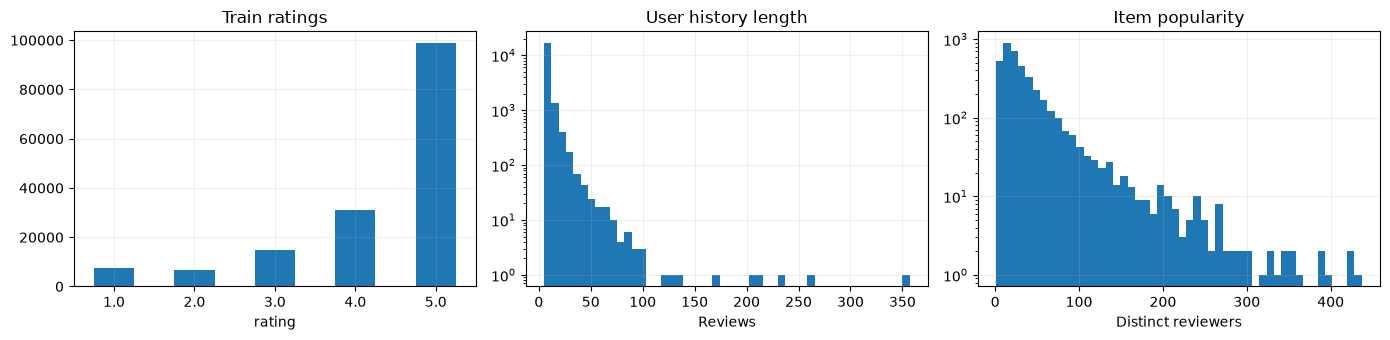

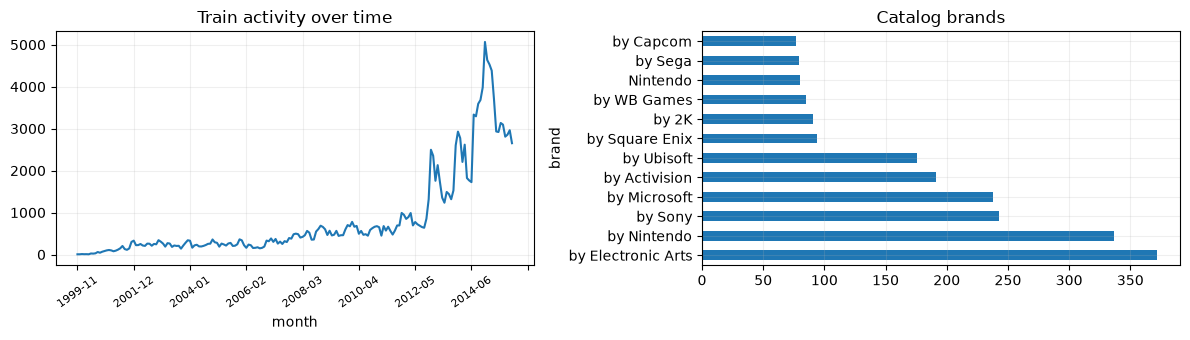

,items
missing_brand,16
missing_category,19


In [4]:
train=data['train']
activity=train.groupby('u').size()
popularity=train.groupby('i').u.nunique()
density=len(train)/(data['shape'][0]*data['shape'][1])
display(pd.Series({'users':data['shape'][0],'items':data['shape'][1],
                   'train_density':density,'train_sparsity':1-density,
                   'exact_duplicate_share':audit['exact_duplicates']/audit['source_rows']}).to_frame('value'))
fig,axes=plt.subplots(1,3,figsize=(14,3.5))
train.rating.value_counts().sort_index().plot.bar(ax=axes[0],title='Train ratings',rot=0)
axes[1].hist(activity,bins=50,log=True);axes[1].set(title='User history length',xlabel='Reviews')
axes[2].hist(popularity,bins=50,log=True);axes[2].set(title='Item popularity',xlabel='Distinct reviewers')
plt.tight_layout();plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
monthly=train.assign(month=pd.to_datetime(train.timestamp,unit='s',utc=True).dt.strftime('%Y-%m')).groupby('month').size()
monthly.plot(ax=axes[0],title='Train activity over time')
axes[0].tick_params(axis='x',rotation=35,labelsize=8)
data['catalog'].brand.replace('',np.nan).value_counts().head(12).plot.barh(ax=axes[1],title='Catalog brands')
plt.tight_layout();plt.show()
display(pd.Series({'missing_brand':int(data['catalog'].brand.eq('').sum()),
                   'missing_category':int(data['catalog'].category.eq('').sum())}).to_frame('items'))

## 3. Протокол оценки

**Разбиение по времени.** В train попадают отзывы до **1 января 2016 года (UTC)**, в validation — за **2016 год**, в test — за **2017 год**. Состав пользователей и каталог определяются по train. Гиперпараметры подбираются на validation, после чего каждая модель заново обучается на train + validation и один раз проверяется на test.

**Общие правила для всех моделей.** Пользователи, товары и правила проверки одинаковы для всех пяти моделей. Рекомендовать можно только товары, у которых в доступной истории уже была хотя бы одна положительная оценка. Всё, что пользователь уже оценивал, из его списка убирается — даже если оценка была низкой.

**Что считается попаданием.** Релевантный товар — это новый для пользователя товар, которому он в следующем периоде поставил **4 или 5**. Новые пользователи и товары, которых не было в обучающей выборке, в сравнение не входят. Пользователи, у которых в следующем периоде нет подходящих положительных оценок, тоже не учитываются в среднем. Сколько пользователей осталось и сколько взаимодействий при этом потеряно, показано отдельно.

Каждая модель ранжирует весь доступный каталог, без случайной подвыборки кандидатов. Если у товаров одинаковый балл, порядок определяется по ID товара.

**Метрики.** Основная метрика — **NDCG@10**: она учитывает не только то, попал ли нужный товар в десятку, но и насколько высоко он стоит. Это важно, потому что пользователь в первую очередь смотрит на верх списка. Вторая метрика — **Recall@10**: какую долю будущих подходящих товаров удалось поймать в первые десять рекомендаций. Обе метрики считаются для каждого пользователя, а затем усредняются:

$$Recall@10_u=\frac{|L_u\cap G_u|}{|G_u|},\qquad NDCG@10_u=\frac{\sum_{r=1}^{10}\mathbf{1}[L_{ur}\in G_u]/\log_2(r+1)}{\sum_{r=1}^{\min(10,|G_u|)}1/\log_2(r+1)}.$$

Здесь $L$ — список рекомендаций, $G$ — множество подходящих будущих товаров, $r$ — позиция в списке. Все настройки выбираются по NDCG@10 на validation, а test используется только для финального сравнения.

In [5]:
validation_protocol=Evaluation(data['train'],data['valid'],data['shape'])
display(pd.Series({'validation_users':len(validation_protocol.users),
                   'validation_positives':sum(map(len,validation_protocol.targets.values())),
                   'candidate_items':int(validation_protocol.candidates.sum())}).to_frame('value'))
print(json.dumps(search_space(),indent=2))

,value
validation_users,2021
validation_positives,4048
candidate_items,3987


{
  "knn": [
    {
      "neighbors": 40,
      "shrinkage": 50.0,
      "min_overlap": 2
    },
    {
      "neighbors": 40,
      "shrinkage": 10.0,
      "min_overlap": 2
    },
    {
      "neighbors": 100,
      "shrinkage": 50.0,
      "min_overlap": 2
    },
    {
      "neighbors": 100,
      "shrinkage": 10.0,
      "min_overlap": 2
    }
  ],
  "ease": [
    {
      "reg": 1000.0
    },
    {
      "reg": 300.0
    },
    {
      "reg": 100.0
    },
    {
      "reg": 30.0
    }
  ],
  "als": [
    {
      "factors": 24,
      "reg": 10.0,
      "alpha": 10.0
    },
    {
      "factors": 24,
      "reg": 1.0,
      "alpha": 10.0
    },
    {
      "factors": 48,
      "reg": 10.0,
      "alpha": 10.0
    },
    {
      "factors": 48,
      "reg": 1.0,
      "alpha": 10.0
    }
  ],
  "halves": [
    180,
    730
  ],
  "als_epochs": [
    5,
    10,
    15
  ],
  "fm": [
    {
      "factors": 16,
      "lr": 0.003
    },
    {
      "factors": 16,
      "lr": 0.01
    },
  

## 4. Пять моделей и подбор гиперпараметров

Все модели написаны с нуля на NumPy и SciPy; ниже коротко описано, что делает каждая.

### Item-based CF

Модель из `models/item_knn.py` ищет похожие товары по тому, какие пользователи поставили им положительные оценки. Сходство — косинусное, но дополнительно умножается на $n_{ij}/(n_{ij}+s)$, где $n_{ij}$ — число общих пользователей. Так случайные совпадения на паре человек получают меньший вес. Связь между товарами учитывается, только если у них минимум два общих пользователя; связь товара с самим собой не учитывается.

Для каждого товара хранится фиксированное число ближайших соседей. Балл кандидата — сумма его сходств с товарами из положительной истории пользователя, то есть в матричном виде $BW$.

### iALS

В `models/ials.py` оценки 4–5 считаются положительным сигналом: $p_{ui}=\mathbf{1}[r_{ui}\ge4]$. Для всех пар, по которым есть отзыв, уверенность $c_{ui}=11$, а для всех остальных — $c=1$ и $p=0$. Благодаря этому низкая оценка — не то же самое, что отсутствие отзыва: если модель даёт высокий балл товару, который пользователю явно не понравился, она штрафуется сильнее.

Модель минимизирует $\sum c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda(\|X\|_F^2+\|Y\|_F^2)$, по очереди обновляя факторы пользователей и товаров через решение систем линейных уравнений. Общие для всех обновлений матричные произведения считаются один раз, поэтому хранить полную матрицу всех пар пользователь–товар не нужно.

### EASE

Модель из `models/ease.py` учится восстанавливать положительную историю пользователя через связи между товарами. У неё есть решение в закрытой форме: $P=(B^\top B+\lambda I)^{-1}$, $W_{ij}=-P_{ij}/P_{jj}$, $W_{jj}=0$. Нулевая диагональ не даёт товару «предсказывать» самого себя.

Обратная матрица считается через разложение Холецкого. Отрицательные веса не обрезаются — в EASE они нормальны. Главный минус модели — память: матрица весов растёт как квадрат числа товаров.

### Факторизационная машина

В `models/fm.py` реализована FM второго порядка:

$$s(x)=\sum_j w_jx_j+\frac12\sum_f\Big[\big(\sum_jv_{jf}x_j\big)^2-\sum_jv_{jf}^2x_j^2\Big].$$

Она учитывает как отдельные признаки, так и их попарные взаимодействия. Обучение идёт на BPR-потерю $\log(1+e^{-(s^+-s^-)})$: балл товара, который пользователю понравился, должен быть выше балла случайного товара без отзыва. Градиенты и шаги Adam написаны вручную.

**Признаки.** Помимо ID пользователя и товара используются: насколько активен пользователь (в интервалах), насколько популярен товар, сколько времени прошло с первого появления товара и календарный месяц. Всё это считается только по событиям, которые произошли *раньше* обучающего примера, — события с той же меткой времени в прошлое не попадают. Так модель не видит информацию, которой не было бы в момент рекомендации.

Отрицательные примеры берутся из товаров, которые к моменту события уже существовали, но которые этот пользователь не оценивал. Ответы из validation и test здесь не используются. Чтобы понять, дают ли признаки что-то сверх ID, отдельно обучается та же FM только на ID.

### ALS с собственным целевым сигналом

В `models/custom_als.py` уверенность $c$ та же, что в базовом iALS, а меняется само целевое значение:

$$q_{ui}=\max\Big(0,\frac{r_{ui}-3}{2}\Big)\left(\frac12+\frac12\,2^{-a_{ui}/h}\right).$$

Здесь $a$ — сколько дней прошло от отзыва до начала следующего периода, $h$ — период полураспада. Идея простая: пятёрка говорит об интересе сильнее, чем четвёрка, а старый отзыв — слабее, чем свежий. При этом давность может ослабить сигнал максимум вдвое, чтобы старая история не обнулялась совсем. Это гипотеза, и проверить её можно только по качеству будущих рекомендаций.

При тех же факторах матрица системы уравнений не меняется, а правая часть превращается из $Y^\top C_up_u$ в $Y^\top C_uq_u$. То есть меняется именно то, что модель пытается предсказать, а не только веса ошибок. Критерий релевантности на test при этом общий для всех моделей.

**Про метаданные каталога.** Названия и категории собраны одним снимком, исторических версий у них нет. Поэтому в FM идут только признаки, которые можно честно восстановить из прошлых взаимодействий. Названия и категории используются для описания данных и в примерах рекомендаций, а наличие названия — ещё и при отборе товаров.

### Как выбираются настройки

Выше выведены все проверяемые значения параметров. Число факторов, регуляризация и число эпох выбираются по NDCG@10 на validation. Если несколько вариантов дают одинаковый результат, остаётся первый по порядку в сетке, а среди эпох — более ранняя.

Выбранные настройки фиксируются до проверки на test. После этого каждая модель заново обучается на train + validation, и по результатам test ничего уже не перенастраивается.

Обе версии FM — с признаками и только с ID — используют одну сетку, один seed, одни и те же положительные пары и одинаковый способ выбора отрицательных примеров. Но лучшие настройки для них выбираются отдельно, поэтому итоговое сравнение показывает разницу двух настроенных моделей, а не чистый эффект признаков.

У ALS с собственным сигналом дополнительно перебираются два значения периода полураспада, так что его сетка шире, чем у базового iALS (число вариантов видно в таблице ниже). Ещё один контрольный вариант — с учётом величины оценки, но без затухания по времени — проверяется только на validation с настройками лучшего базового iALS. Он помогает понять, какая часть нового сигнала работает.

In [6]:
results=run_experiments(data)

validation ItemKNN {'neighbors': 40, 'shrinkage': 50.0, 'min_overlap': 2}: NDCG=0.027156


validation ItemKNN {'neighbors': 40, 'shrinkage': 10.0, 'min_overlap': 2}: NDCG=0.027740


validation ItemKNN {'neighbors': 100, 'shrinkage': 50.0, 'min_overlap': 2}: NDCG=0.027011


validation ItemKNN {'neighbors': 100, 'shrinkage': 10.0, 'min_overlap': 2}: NDCG=0.027306


validation EASE {'reg': 1000.0}: NDCG=0.027301


...

test ItemKNN: NDCG=0.024575, Recall=0.045572


test iALS: NDCG=0.033222, Recall=0.059946


test EASE: NDCG=0.032845, Recall=0.060861


test FM metadata: NDCG=0.020102, Recall=0.050097


test CustomALS: NDCG=0.031459, Recall=0.060420


In [7]:
validation_results=results['validation']
display(validation_results.groupby('model').agg(trials=('model','size'),
                         best_validation_NDCG=('NDCG@10','max')))
display(pd.DataFrame([{'model':name,**v['params'],'validation_NDCG':v['metric']}
                      for name,v in results['settings']['selected'].items()]))
display(results['grade_control'])

model,trials,best_validation_NDCG
ItemKNN,4,0.027740
EASE,4,0.032304
iALS,12,0.031538
CustomALS,24,0.039559
FM metadata,12,0.030860


model,neighbors,shrinkage,min_overlap,validation_NDCG,factors,reg,alpha,epochs,lr,half_life_days
ItemKNN,40.0,10.0,2.0,0.027740,NaN,NaN,NaN,NaN,NaN,NaN
iALS,NaN,NaN,NaN,0.031538,48.0,1.0,10.0,10.0,NaN,NaN
EASE,NaN,NaN,NaN,0.032304,NaN,100.0,NaN,NaN,NaN,NaN
FM metadata,NaN,NaN,NaN,0.030860,16.0,NaN,NaN,3.0,0.003,NaN
CustomALS,NaN,NaN,NaN,0.039559,48.0,10.0,10.0,10.0,NaN,180.0


model,settings,NDCG@10,Recall@10,eval_users,eligible_positives,candidate_items,coverage,retrieval_seconds
"ALS graded, no decay","{""factors"": 48, ""reg"": 1.0, ""alpha"": 10.0, ""epochs"": 10}",0.031365,0.050927,2021,4048,3987,0.228743,0.571558


## 5. Сравнение моделей

В основной таблице — результаты всех пяти моделей при K=10 и выбранные для них параметры. Все модели проверяются на одних и тех же пользователях, с одинаковыми кандидатами и одинаковым набором подходящих будущих товаров.

Рядом показаны охват каталога, время обучения и размер параметров. Отдельная таблица сравнивает две версии FM: с признаками и только с ID.

Для разниц между вариантами построены интервалы парным bootstrap: пользователи многократно перевыбираются с возвращением, и в каждой такой выборке обе модели оцениваются на одних и тех же людях. Интервалы показывают, насколько результат устойчив на этой группе пользователей. О том, повторится ли он в другие годы или с другим seed, они ничего не говорят.

In [7]:
display(results['test'][['model','NDCG@10','Recall@10','coverage','eval_users',
                         'eligible_positives','candidate_items','final_fit_seconds','parameter_MiB','settings']])
display(results['fm_ablation'][['model','NDCG@10','Recall@10','coverage']].rename(columns={'model':'Режим FM'}))
display(results['bootstrap'])

model,NDCG@10,Recall@10,coverage,eval_users,eligible_positives,candidate_items,final_fit_seconds,parameter_MiB,settings
ItemKNN,0.024575,0.045572,0.368104,878,1448,3988,0.583382,1.077545,"{""min_overlap"": 2, ""neighbors"": 40, ""shrinkage"": 10.0}"
iALS,0.033222,0.059946,0.207874,878,1448,3988,9.183996,8.402710,"{""alpha"": 10.0, ""epochs"": 10, ""factors"": 48, ""reg"": 1.0}"
EASE,0.032845,0.060861,0.351805,878,1448,3988,3.037631,121.643440,"{""reg"": 100.0}"
FM metadata,0.020102,0.050097,0.005767,878,1448,3988,4.250450,2.980888,"{""epochs"": 3, ""factors"": 16, ""lr"": 0.003}"
CustomALS,0.031459,0.060420,0.191073,878,1448,3988,8.502677,8.402710,"{""alpha"": 10.0, ""epochs"": 10, ""factors"": 48, ""half_life_days"": 180, ""reg"": 10.0}"


Режим FM,NDCG@10,Recall@10,coverage
FM IDs,0.034170,0.069998,0.092026
FM metadata,0.020102,0.050097,0.005767


comparison,mean_delta,lower,upper
CustomALS minus iALS,-0.001762,-0.006625,0.003137
FM metadata minus FM IDs,-0.014068,-0.022713,-0.005205


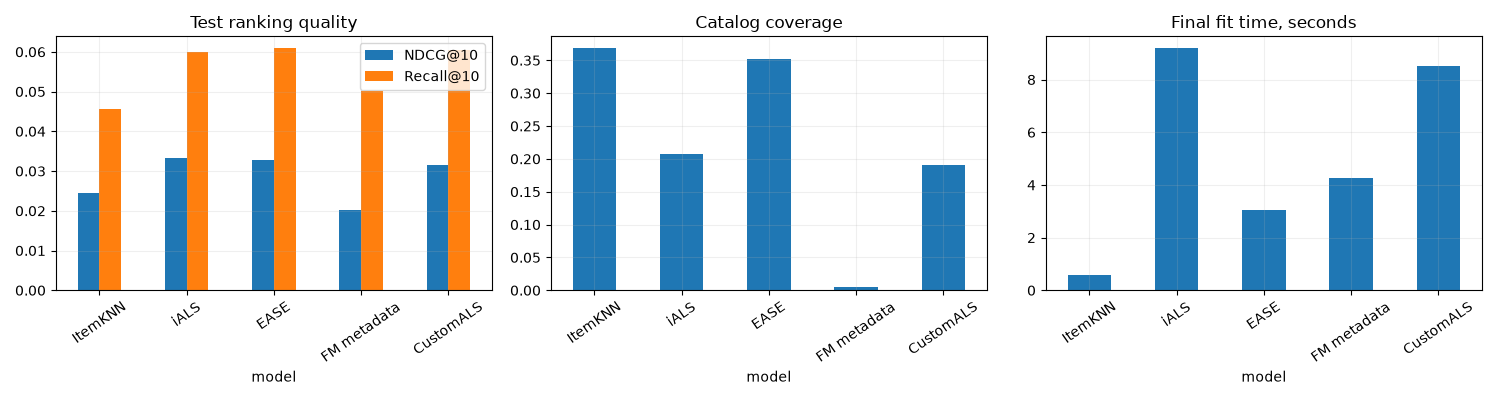

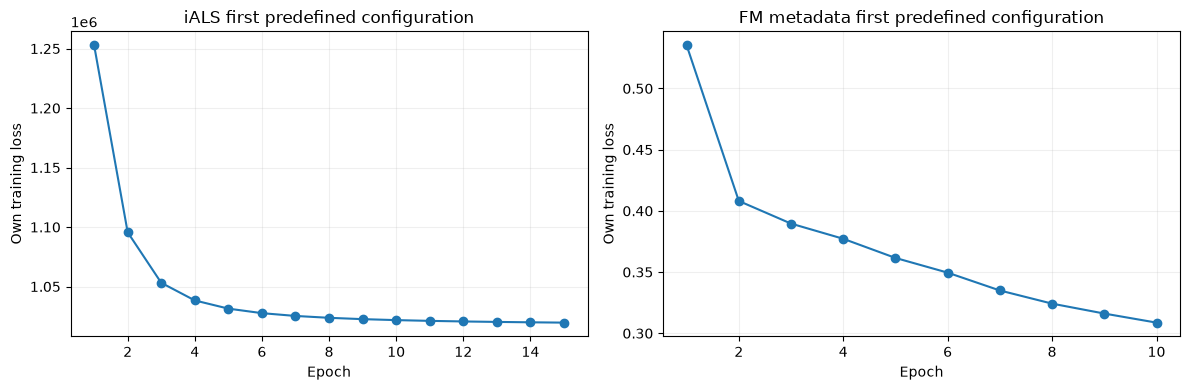

model,history_group,users,NDCG@10
ItemKNN,1–10,556,0.025419
ItemKNN,11–30,280,0.025205
ItemKNN,31+,42,0.009211
iALS,1–10,556,0.030678
iALS,11–30,280,0.042954
iALS,31+,42,0.002007
EASE,1–10,556,0.031392
EASE,11–30,280,0.039530
EASE,31+,42,0.007511
FM metadata,1–10,556,0.021655


In [8]:
table=results['test'].set_index('model')
fig,axes=plt.subplots(1,3,figsize=(15,4))
table[['NDCG@10','Recall@10']].plot.bar(ax=axes[0],title='Test ranking quality')
table.coverage.plot.bar(ax=axes[1],title='Catalog coverage')
table.final_fit_seconds.plot.bar(ax=axes[2],title='Final fit time, seconds')
for ax in axes:ax.tick_params(axis='x',rotation=40)
plt.tight_layout();plt.show()
curves=results['curves']
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name,ax in [('iALS',axes[0]),('FM metadata',axes[1])]:
    group=curves[curves.model==name]
    first=group.settings.iloc[0]
    g=group[group.settings==first]
    ax.plot(g.epoch,g.loss,marker='o');ax.set(title=name+' first predefined configuration',xlabel='Epoch',ylabel='Own training loss')
plt.tight_layout();plt.show()
group_rows=[]
for name,details in results['details'].items():
    details=details.copy()
    details['history_group']=pd.cut(details.history_length,[0,10,30,np.inf],labels=['1–10','11–30','31+'])
    for label,part in details.groupby('history_group',observed=True):
        group_rows.append({'model':name,'history_group':str(label),'users':len(part),'NDCG@10':part['NDCG@10'].mean()})
display(pd.DataFrame(group_rows))

### Примеры рекомендаций

Ниже показаны последние оценки и рекомендации двух первых по ID пользователей из тестовой группы. Они выбраны без оглядки на то, насколько удачными получились их рекомендации. Названия нужны, чтобы было проще понять списки; балл модели при этом не является вероятностью покупки.

In [9]:
examples=[]
catalog=data['catalog'].set_index('i')
for u in results['test_eval'].users[:2]:
    recent=pd.concat([data['train'],data['valid']]).query('u == @u').sort_values('timestamp').tail(5)
    display(pd.DataFrame({'user':int(u),'past_title':catalog.loc[recent.i,'title'].to_numpy(),
                          'past_rating':recent.rating.to_numpy()}))
    for name in ['ItemKNN','iALS','EASE','FM metadata','CustomALS']:
        for rank,i in enumerate(results['recommendations'][name][int(u)],1):
            examples.append({'user':int(u),'model':name,'rank':rank,'title':catalog.loc[i,'title'],
                             'future_relevant':int(i in results['test_eval'].targets[int(u)])})
display(pd.DataFrame(examples))

,user,past_title,past_rating
0,1,Sonic the Hedgehog - Playstation 3,5.0
1,1,PlayStation Move Essentials Pack,5.0
2,1,PS3 Move Charge Station Quad Port Charging Dock,5.0
3,1,Just Dance 3 - Playstation 3,5.0
4,1,Just Dance 4 - Playstation 3,5.0


,user,past_title,past_rating
0,54,Final Fantasy X,2.0
1,54,Microsoft Flight Simulator 2004: A Century of ...,5.0
2,54,Dante's Inferno - Xbox 360,3.0
3,54,PDP Pelican PS3 Dual Triggers with Bonus Silic...,5.0
4,54,Hisurprise 2x Black Battery Cover for Microsof...,5.0


,user,model,rank,title,future_relevant
0,1,ItemKNN,1,Just Dance 2014 - Playstation 3,0
1,1,ItemKNN,2,Sports Champions 2 - Playstation 3,0
2,1,ItemKNN,3,PS3 Everybody Dance,0
3,1,ItemKNN,4,Sony PlayStation 3 Move Motion Controller (Bul...,0
4,1,ItemKNN,5,Sonic Generations - PlayStation 3,0
...,...,...,...,...,...
95,54,CustomALS,6,Fallout 4 - PlayStation 4,0
96,54,CustomALS,7,Demon's Souls,0
97,54,CustomALS,8,PlayStation 2 Console Slim PS2,0
98,54,CustomALS,9,Xbox 360 Rechargeable Battery 2-Pack,0


## 6. Выводы

In [10]:
winner=table['NDCG@10'].idxmax()
fm_comparison=results['fm_ablation'].set_index('model')
metadata_delta=fm_comparison.loc['FM metadata','NDCG@10']-fm_comparison.loc['FM IDs','NDCG@10']
target_delta=table.loc['CustomALS','NDCG@10']-table.loc['iALS','NDCG@10']
display(Markdown(f"Лучший NDCG@10 в этом запуске: **{winner}**, **{table.loc[winner,'NDCG@10']:.5f}**. "
                 f"Разница FM с метапризнаками и FM только с ID: **{metadata_delta:+.5f}**. "
                 f"Разница Custom ALS и базового iALS: **{target_delta:+.5f}**. "
                 "Это сравнение выбранных на validation настроек; границы неопределённости показаны выше."))
for row in results['bootstrap'].itertuples():
    interpretation='интервал включает ноль, устойчивое отличие на этой группе не установлено' if row.lower<=0<=row.upper else 'интервал не включает ноль на этой проверочной группе'
    print(row.comparison,':',interpretation)
source_hashes={p.as_posix():hashlib.sha256(p.read_bytes()).hexdigest()
               for folder in ['models','utils'] for p in sorted(Path(folder).glob('*.py'))}
manifest={'seed':SEED,'python':platform.python_version(),'platform':platform.platform(),
          'execution_environment':'Google Colab' if 'google.colab' in sys.modules else 'local verification',
          'versions':versions,'source_hashes':source_hashes,'data_audit':audit,
          'source_files':{name:{'url':v[0],'bytes':v[1],'sha256':v[2]} for name,v in FILES.items()},
          'split_rows':split_table.to_dict('records')}
print('Среда выполнения:',manifest['execution_environment'])

Лучший NDCG@10 среди пяти моделей: **iALS**, **0.03322**. Разница FM с метапризнаками и той же FM только с ID: **-0.01407**. Разница Custom ALS и базового iALS: **-0.00176**.

CustomALS minus iALS : интервал включает ноль, устойчивое отличие на этой группе не установлено
FM metadata minus FM IDs : интервал не включает ноль на этой проверочной группе
Среда выполнения: local verification


### Результаты сравнения

**Лучшие модели.** По NDCG@10 первым оказался iALS — 0,03322. EASE почти рядом: 0,03284, а по Recall@10 он даже немного впереди (0,06086 против 0,05995). Разница настолько мала, что по одному эксперименту нельзя уверенно назвать лучшую из этих двух моделей. У iALS выбраны 48 факторов, регуляризация 1 и 10 эпох, у EASE — регуляризация 100.

**Метапризнаки в FM.** FM с историческими признаками уступила той же FM только на ID: 0,02010 против 0,03417 по NDCG@10. Но настройки у этих версий подбирались отдельно, поэтому всю разницу нельзя списать на признаки. На validation при одних и тех же настройках признаки иногда помогали, а иногда мешали. Вывод такой: в этой работе после подбора параметров признаки выигрыша не дали, но утверждать, что они бесполезны вообще, было бы слишком смело.

**Собственный целевой сигнал.** На validation ALS с новым сигналом выглядел заметно лучше базового, но на test преимущество не подтвердилось: 0,03146 против 0,03322. Интервал разницы включает ноль, так что говорить об улучшении нельзя. К тому же у финальных версий разная регуляризация, поэтому результат относится к выбранным конфигурациям, а не только к формуле сигнала.

**Главное ограничение — выборка.** Финальная оценка проведена на 878 пользователях, у которых в 2017 году нашлись подходящие положительные оценки. После всех фильтров осталось около 0,71% положительных взаимодействий тестового периода. Поэтому выводы относятся к этой группе пользователей и товаров, а не ко всему Amazon.
